# Forecasting Atmospheric CO₂ with an LSTM Network (PyTorch)
**Made by Ing. Cristian Misael Torres Martínez**

**Time Series Forecasting — Project U3–U4**

**Data:** monthly mean atmospheric CO₂ at Mauna Loa Observatory, Hawaii (NOAA Global Monitoring Laboratory), March 1958 – September 2026.

**Contents**
1. Quick exploratory analysis
2. Pre-processing and sliding windows
3. LSTM model in PyTorch (and a simple RNN for reference)
4. Forecasts on the last 10 years: one-step-ahead and recursive
5. Comparison with non-neural models: seasonal naive + drift, SARIMA, Holt-Winters, LightGBM
6. Looking ahead: forecast to 2036

In [4]:
%pip install lightgbm
%pip install lightgbm torch statsmodels pandas matplotlib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [5]:
import time, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.graphics.tsaplots import plot_acf
from lightgbm import LGBMRegressor

SEED = 42
def set_seed(seed=SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)
set_seed()
torch.use_deterministic_algorithms(True)

plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"actual": "#1f2937", "LSTM": "#e8590c", "RNN": "#7048e8", "SARIMA": "#1c7ed6",
          "Holt-Winters": "#2b8a3e", "LightGBM": "#f59f00", "Seasonal naive + drift": "#868e96"}
T0 = time.time()
print("PyTorch", torch.__version__)

PyTorch 2.8.0+cpu


## 1. Quick exploratory analysis

In [6]:
raw = pd.read_csv("co2_mm_mlo.csv", comment="#")
raw["ds"] = pd.to_datetime(dict(year=raw.year, month=raw.month, day=1))
df = raw[["ds", "average", "deseasonalized", "sdev"]].rename(columns={"average": "y"})
df["interpolated"] = (raw["sdev"] < 0) & (raw["year"] >= 1975)   # NOAA marks filled months with negative sdev
y, dates = df["y"].values, df["ds"]
n = len(y)
print(f"{n} months: {dates.iloc[0]:%b %Y} to {dates.iloc[-1]:%b %Y}")
print("Months interpolated by NOAA after 1975:", int(df["interpolated"].sum()))
df.tail()

823 months: Mar 1958 to Sep 2026
Months interpolated by NOAA after 1975: 2


,ds,y,deseasonalized,sdev,interpolated
818,2026-05-01,432.34,429.05,0.64,False
819,2026-06-01,431.43,429.00,0.27,False
820,2026-07-01,429.13,428.74,0.61,False
821,2026-08-01,427.55,429.48,0.38,False
822,2026-09-01,426.07,429.55,0.51,False


In [7]:
first_400 = df.loc[df.y >= 400, "ds"].iloc[0]
first_420 = df.loc[df.y >= 420, "ds"].iloc[0]
facts = pd.Series({
    "First value (Mar 1958), ppm": y[0],
    "Latest value (Sep 2026), ppm": y[-1],
    "Highest monthly value, ppm": y.max(),
    "Month of highest value": f"{dates.iloc[y.argmax()]:%b %Y}",
    "Total increase, ppm": y[-1] - y[0],
    "Total increase, %": 100 * (y[-1] / y[0] - 1),
    "First month above 400 ppm": f"{first_400:%b %Y}",
    "First month above 420 ppm": f"{first_420:%b %Y}",
})
facts

First value (Mar 1958), ppm        315.71
Latest value (Sep 2026), ppm       426.07
Highest monthly value, ppm         432.34
Month of highest value           May 2026
Total increase, ppm                110.36
Total increase, %               34.956131
First month above 400 ppm        May 2013
First month above 420 ppm        Apr 2022
dtype: object

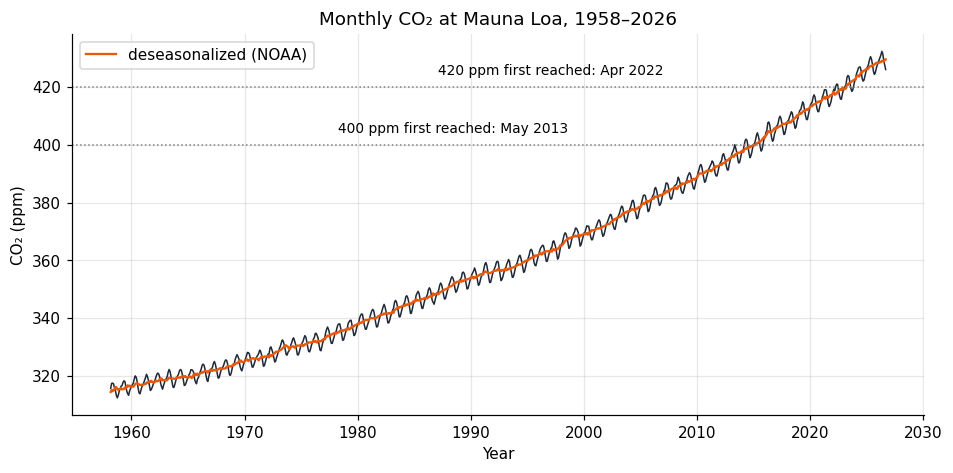

In [8]:
fig, ax = plt.subplots()
ax.plot(dates, y, color=COLORS["actual"], lw=1)
ax.plot(dates, df["deseasonalized"], color=COLORS["LSTM"], lw=1.5, label="deseasonalized (NOAA)")
for level, d in [(400, first_400), (420, first_420)]:
    ax.axhline(level, color="gray", ls=":", lw=1)
    ax.annotate(f"{level} ppm first reached: {d:%b %Y}", (d, level), xytext=(-260, 8), textcoords="offset points", fontsize=9)
ax.set(title="Monthly CO₂ at Mauna Loa, 1958–2026", xlabel="Year", ylabel="CO₂ (ppm)")
ax.legend(loc="upper left")
plt.show()

**The growth is accelerating:** the yearly increase (Jan–Dec mean vs previous year) has grown decade after decade.

Largest yearly increase: 3.52 ppm in 2024


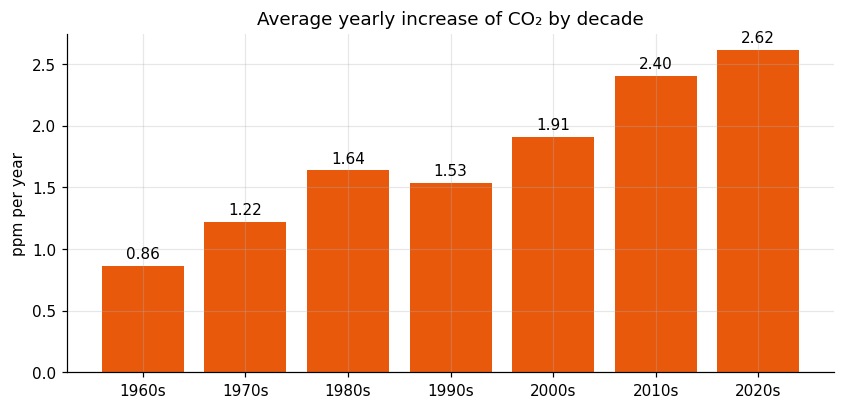

ds
1960    0.86
1970    1.22
1980    1.64
1990    1.53
2000    1.91
2010    2.40
2020    2.62
Name: y, dtype: float64

In [9]:
annual = df[(df.ds.dt.year >= 1959) & (df.ds.dt.year <= 2025)].groupby(df.ds.dt.year)["y"].mean()
growth = annual.diff().dropna()
decade = growth.groupby((growth.index // 10) * 10).mean()
print(f"Largest yearly increase: {growth.max():.2f} ppm in {growth.idxmax()}")

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar([f"{d}s" for d in decade.index], decade.values, color=COLORS["LSTM"])
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set(title="Average yearly increase of CO₂ by decade", ylabel="ppm per year")
plt.show()
decade.round(2)

**Seasonality:** every year CO₂ peaks in May and reaches its minimum in September–October (Northern Hemisphere vegetation absorbs CO₂ in summer).

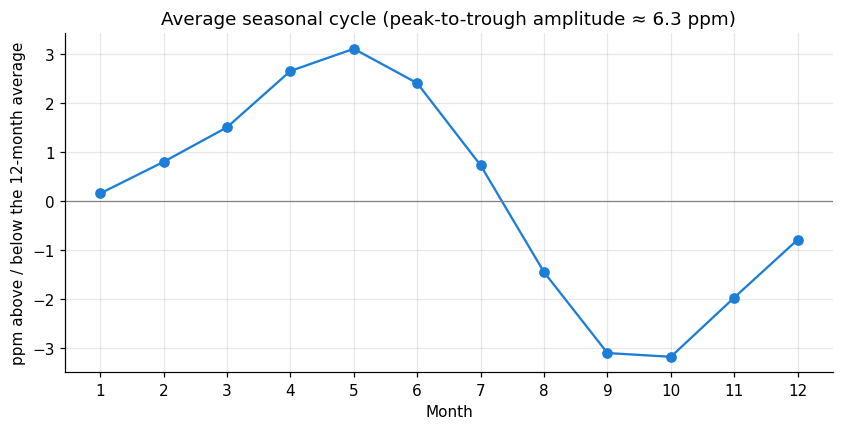

Peak month: 5 | minimum month: 10


In [10]:
detr = df.y - df.y.rolling(12, center=True).mean()
season = detr.groupby(df.ds.dt.month).mean()
amp = season.max() - season.min()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(season.index, season.values, marker="o", color=COLORS["SARIMA"])
ax.axhline(0, color="gray", lw=.8)
ax.set(title=f"Average seasonal cycle (peak-to-trough amplitude ≈ {amp:.1f} ppm)", xlabel="Month",
       ylabel="ppm above / below the 12-month average", xticks=range(1, 13))
plt.show()
print("Peak month:", season.idxmax(), "| minimum month:", season.idxmin())

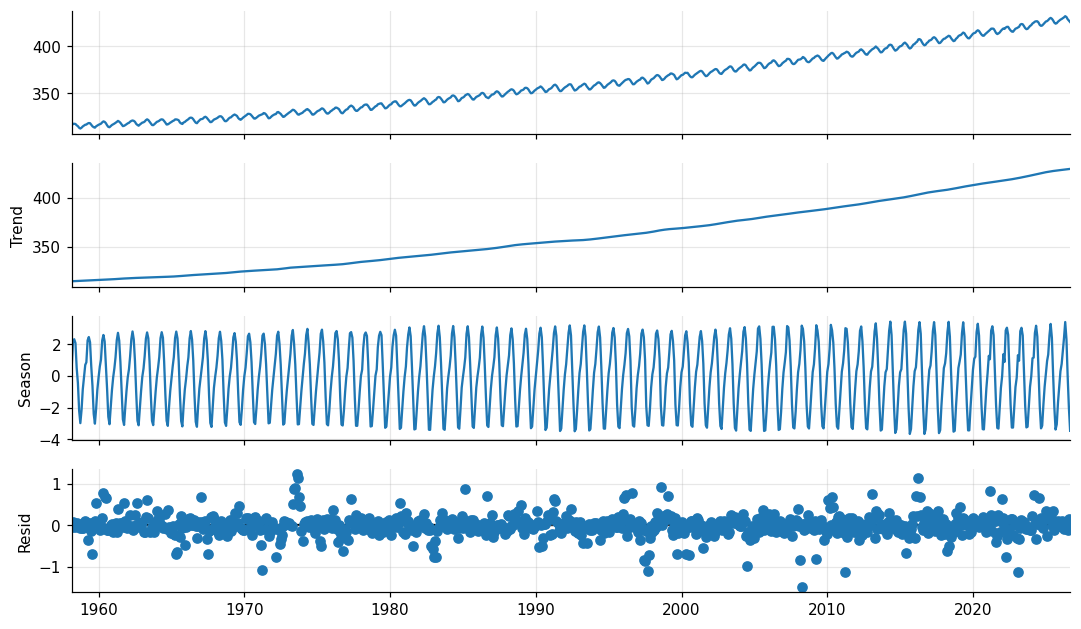

In [11]:
stl = STL(pd.Series(y, index=dates), period=12, robust=True).fit()
fig = stl.plot()
fig.set_size_inches(10, 6)
plt.show()

**Stationarity:** the ACF of the raw series decays very slowly (trend), while the ACF of the month-to-month change shows the yearly cycle (lag 12).
This is why the series is differenced before training (Section 2).

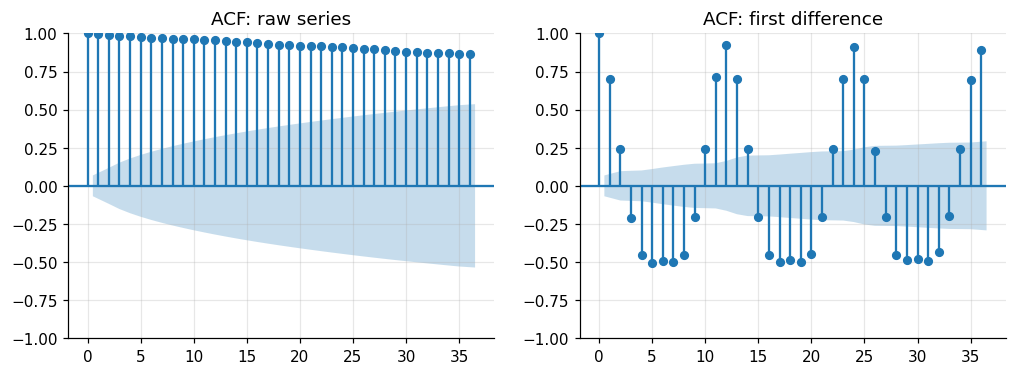

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
plot_acf(y, lags=36, ax=axes[0]); axes[0].set_title("ACF: raw series")
plot_acf(np.diff(y), lags=36, ax=axes[1]); axes[1].set_title("ACF: first difference")
plt.show()

## 2. Train / test split, pre-processing and sliding windows

In [13]:
H = 120                                   # test = last 10 years
LOOKBACK = 24                             # each input window = 24 months
n_train = n - H
split = dates.iloc[n_train]
actual, test_dates = y[n_train:], dates.iloc[n_train:]
print(f"Train: {dates.iloc[0]:%b %Y} – {dates.iloc[n_train-1]:%b %Y} ({n_train} months)")
print(f"Test : {split:%b %Y} – {dates.iloc[-1]:%b %Y} ({H} months)")

# First difference (monthly change) + standardization with TRAIN statistics only
d = np.diff(y)                            # d[t-1] = y[t] - y[t-1]
n_train_d = n_train - 1
mu, sd = d[:n_train_d].mean(), d[:n_train_d].std()
z = (d - mu) / sd

def make_windows(series, lookback=LOOKBACK):
    """Sliding window: [s(t-24) ... s(t-1)] -> s(t)"""
    X = np.array([series[i - lookback:i] for i in range(lookback, len(series))])
    return X, series[lookback:]

X, Y = make_windows(z)
is_train = np.arange(LOOKBACK, len(z)) < n_train_d
X_train, Y_train, X_test = X[is_train], Y[is_train], X[~is_train]
print("Training windows:", X_train.shape, "| test windows:", X_test.shape)

def to_level(pred_changes, start):        # changes (standardized) -> CO2 levels
    return start + np.cumsum(pred_changes * sd + mu)

Train: Mar 1958 – Sep 2016 (703 months)
Test : Oct 2016 – Sep 2026 (120 months)
Training windows: (678, 24) | test windows: (120, 24)


## 3. LSTM in PyTorch
**Encoder–decoder view:** the LSTM reads the 24-month window and summarizes it in its final hidden state (encoder);
a linear layer turns that summary into next month's change (decoder).
The same class builds a simple RNN for reference: same input, same size, but without the cell state and gates.

In [14]:
class Forecaster(nn.Module):
    def __init__(self, cell="lstm", hidden=64):
        super().__init__()
        rnn = nn.LSTM if cell == "lstm" else nn.RNN
        self.encoder = rnn(input_size=1, hidden_size=hidden, batch_first=True)
        self.decoder = nn.Linear(hidden, 1)

    def forward(self, x):                 # x: (batch, 24, 1)
        out, _ = self.encoder(x)          # hidden state at every step
        return self.decoder(out[:, -1]).squeeze(-1)   # use the last one

def train(cell, Xtr, Ytr, hidden=64, epochs=300, patience=20, lr=1e-3, batch=32):
    set_seed()
    model = Forecaster(cell, hidden)
    Xt = torch.tensor(Xtr, dtype=torch.float32).unsqueeze(-1)
    Yt = torch.tensor(Ytr, dtype=torch.float32)
    n_val = int(len(Xt) * 0.15)           # last 15% of training windows = validation
    Xa, Ya, Xv, Yv = Xt[:-n_val], Yt[:-n_val], Xt[-n_val:], Yt[-n_val:]
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    g = torch.Generator().manual_seed(SEED)
    best, best_state, wait, hist = np.inf, None, 0, {"train": [], "val": []}
    for epoch in range(epochs):
        model.train()
        for idx in torch.randperm(len(Xa), generator=g).split(batch):
            opt.zero_grad()
            loss = loss_fn(model(Xa[idx]), Ya[idx])
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            tl, vl = loss_fn(model(Xa), Ya).item(), loss_fn(model(Xv), Yv).item()
        hist["train"].append(tl); hist["val"].append(vl)
        if vl < best:
            best, best_state, wait = vl, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, hist

def predict(model, Xw):
    with torch.no_grad():
        return model(torch.tensor(Xw, dtype=torch.float32).unsqueeze(-1)).numpy()

def recursive(model_fn, history, steps=H):
    """Feed each prediction back as input for the next month."""
    window, out = list(history[-LOOKBACK:]), []
    for _ in range(steps):
        p = float(model_fn(np.array(window[-LOOKBACK:])[None, :]))
        out.append(p); window.append(p)
    return np.array(out)

t = time.time()
lstm, hist_lstm = train("lstm", X_train, Y_train)
print(f"LSTM: {len(hist_lstm['val'])} epochs, {time.time()-t:.1f} s, "
      f"{sum(p.numel() for p in lstm.parameters()):,} parameters")
t = time.time()
rnn, hist_rnn = train("rnn", X_train, Y_train)
print(f"RNN : {len(hist_rnn['val'])} epochs, {time.time()-t:.1f} s, "
      f"{sum(p.numel() for p in rnn.parameters()):,} parameters")

LSTM: 116 epochs, 9.5 s, 17,217 parameters
RNN : 213 epochs, 15.1 s, 4,353 parameters


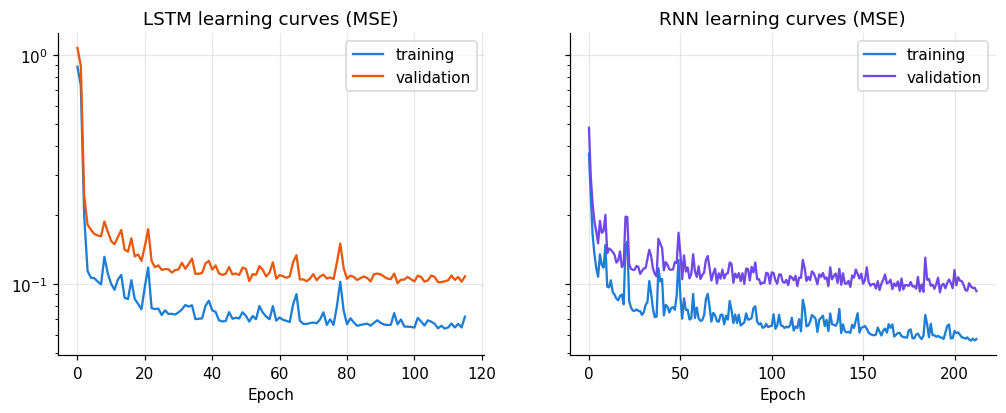

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (name, h) in zip(axes, [("LSTM", hist_lstm), ("RNN", hist_rnn)]):
    ax.plot(h["train"], label="training", color="#1c7ed6")
    ax.plot(h["val"], label="validation", color=COLORS[name])
    ax.set(title=f"{name} learning curves (MSE)", xlabel="Epoch", yscale="log")
    ax.legend()
plt.show()

## 4. Forecasts on the test period (Oct 2016 – Sep 2026)
* **One-step-ahead:** each month is predicted from the real previous 24 months.
* **Recursive:** the model only sees data until Sep 2016 and forecasts 120 months, feeding each prediction back.

In [16]:
preds_one, preds_rec = {}, {}
prev = y[n_train - 1:n - 1]                              # real value of the previous month

for name, m in [("LSTM", lstm), ("RNN", rnn)]:
    preds_one[name] = prev + predict(m, X_test) * sd + mu
    preds_rec[name] = to_level(recursive(lambda w, m=m: predict(m, w)[0], z[:n_train_d]), y[n_train - 1])

# Lesson: the same LSTM trained on raw levels (no differencing)
mu_l, sd_l = y[:n_train].mean(), y[:n_train].std()
Xl, Yl = make_windows((y - mu_l) / sd_l)
tr_l = np.arange(LOOKBACK, n) < n_train
lstm_raw, _ = train("lstm", Xl[tr_l], Yl[tr_l])
raw_one = predict(lstm_raw, Xl[~tr_l]) * sd_l + mu_l

### Non-neural models

In [17]:
ytr = pd.Series(y[:n_train], index=pd.DatetimeIndex(dates[:n_train], freq="MS"))
yall = pd.Series(y, index=pd.DatetimeIndex(dates, freq="MS"))

# Seasonal naive + drift: value 12 months earlier + average yearly increase in training
drift = (y[n_train - 1] - y[0]) / (n_train - 1) * 12
preds_one["Seasonal naive + drift"] = y[n_train - 12:n - 12] + drift
preds_rec["Seasonal naive + drift"] = np.tile(y[n_train - 12:n_train], H // 12) + drift * np.repeat(np.arange(1, H // 12 + 1), 12)

# SARIMA(1,1,1)(0,1,1)12, the classic model for this series
sarima = SARIMAX(ytr, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
preds_rec["SARIMA"] = sarima.forecast(H).values
preds_one["SARIMA"] = sarima.append(yall.iloc[n_train:]).predict(start=n_train, end=n - 1).values

# Holt-Winters: level + additive trend + additive yearly seasonality
hw = ExponentialSmoothing(ytr, trend="add", seasonal="add", seasonal_periods=12).fit()
preds_rec["Holt-Winters"] = hw.forecast(H).values
hw_full = ExponentialSmoothing(yall, trend="add", seasonal="add", seasonal_periods=12, initialization_method="known",
                               initial_level=hw.params["initial_level"], initial_trend=hw.params["initial_trend"],
                               initial_seasonal=hw.params["initial_seasons"]).fit(
    smoothing_level=hw.params["smoothing_level"], smoothing_trend=hw.params["smoothing_trend"],
    smoothing_seasonal=hw.params["smoothing_seasonal"], optimized=False)
preds_one["Holt-Winters"] = hw_full.fittedvalues.values[n_train:]

# LightGBM (gradient-boosted trees) on the same 24-month windows of differenced data
gbm = LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15, random_state=SEED, verbose=-1)
gbm.fit(X_train, Y_train)
preds_one["LightGBM"] = prev + gbm.predict(X_test) * sd + mu
preds_rec["LightGBM"] = to_level(recursive(lambda w: gbm.predict(w)[0], z[:n_train_d]), y[n_train - 1])

  File "c:\Users\crist\AppData\Local\Programs\Python\Python39\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\crist\AppData\Local\Programs\Python\Python39\lib\subprocess.py", line 505, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\crist\AppData\Local\Programs\Python\Python39\lib\subprocess.py", line 951, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\crist\AppData\Local\Programs\Python\Python39\lib\subprocess.py", line 1420, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


## 5. Results and comparison

In [18]:
def metrics(a, p):
    e = a - p
    return {"RMSE": np.sqrt(np.mean(e**2)), "MAE": np.mean(np.abs(e)),
            "MAPE (%)": 100 * np.mean(np.abs(e / a)), "R²": 1 - np.sum(e**2) / np.sum((a - a.mean())**2)}

order = ["LSTM", "RNN", "SARIMA", "Holt-Winters", "LightGBM", "Seasonal naive + drift"]
table_one = pd.DataFrame({m: metrics(actual, preds_one[m]) for m in order}).T
table_one.loc["LSTM on raw levels"] = metrics(actual, raw_one)
table_rec = pd.DataFrame({m: metrics(actual, preds_rec[m]) for m in order}).T
print("A. ONE-STEP-AHEAD (sorted by RMSE)")
display(table_one.sort_values("RMSE").round(3))
print("B. RECURSIVE 10-YEAR FORECAST (sorted by RMSE)")
display(table_rec.sort_values("RMSE").round(3))

A. ONE-STEP-AHEAD (sorted by RMSE)


,RMSE,MAE,MAPE (%),R²
SARIMA,0.340,0.274,0.066,0.998
Holt-Winters,0.349,0.279,0.067,0.998
RNN,0.409,0.332,0.080,0.997
LightGBM,0.420,0.348,0.083,0.997
LSTM,0.424,0.348,0.083,0.997
Seasonal naive + drift,1.233,1.072,0.257,0.974
LSTM on raw levels,21.571,20.434,4.869,-6.884


B. RECURSIVE 10-YEAR FORECAST (sorted by RMSE)


,RMSE,MAE,MAPE (%),R²
SARIMA,1.686,1.356,0.321,0.952
Holt-Winters,1.766,1.438,0.341,0.947
LightGBM,2.497,2.060,0.488,0.894
RNN,3.847,3.226,0.765,0.749
LSTM,6.044,5.234,1.242,0.381
Seasonal naive + drift,6.399,5.556,1.320,0.306


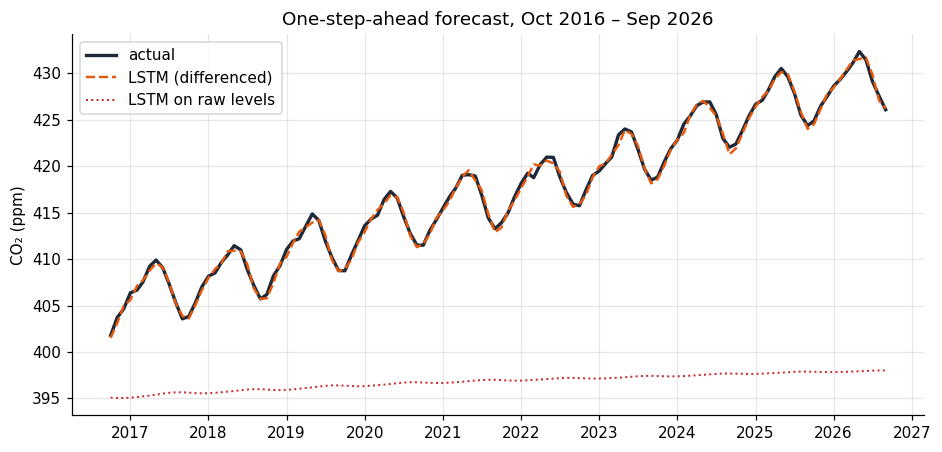

In [19]:
fig, ax = plt.subplots()
ax.plot(test_dates, actual, color=COLORS["actual"], lw=2.2, label="actual")
ax.plot(test_dates, preds_one["LSTM"], color=COLORS["LSTM"], lw=1.6, ls="--", label="LSTM (differenced)")
ax.plot(test_dates, raw_one, color="#c92a2a", lw=1.3, ls=":", label="LSTM on raw levels")
ax.set(title="One-step-ahead forecast, Oct 2016 – Sep 2026", ylabel="CO₂ (ppm)")
ax.legend(loc="upper left")
plt.show()

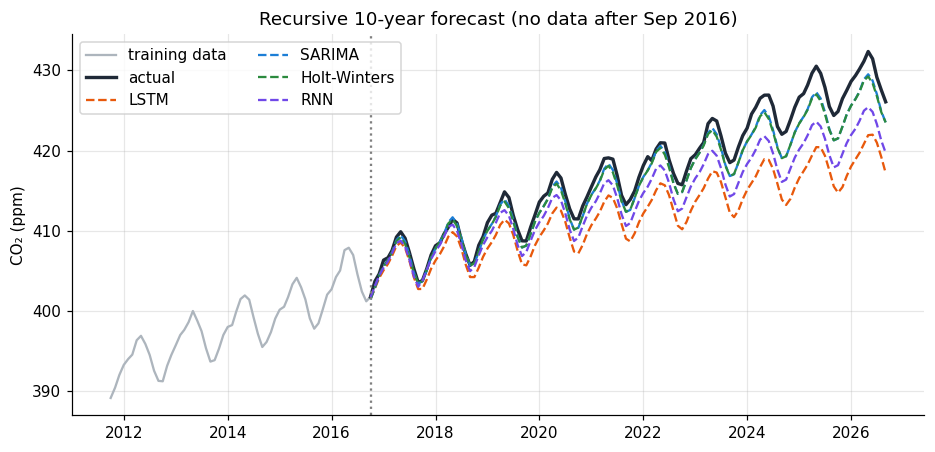

In [20]:
fig, ax = plt.subplots()
ax.plot(dates[n_train - 60:n_train + 1], y[n_train - 60:n_train + 1], color="#adb5bd", lw=1.5, label="training data")
ax.plot(test_dates, actual, color=COLORS["actual"], lw=2.2, label="actual")
for m in ["LSTM", "SARIMA", "Holt-Winters", "RNN"]:
    ax.plot(test_dates, preds_rec[m], color=COLORS[m], lw=1.5, ls="--", label=m)
ax.axvline(split, color="gray", ls=":")
ax.set(title="Recursive 10-year forecast (no data after Sep 2016)", ylabel="CO₂ (ppm)")
ax.legend(loc="upper left", ncol=2)
plt.show()

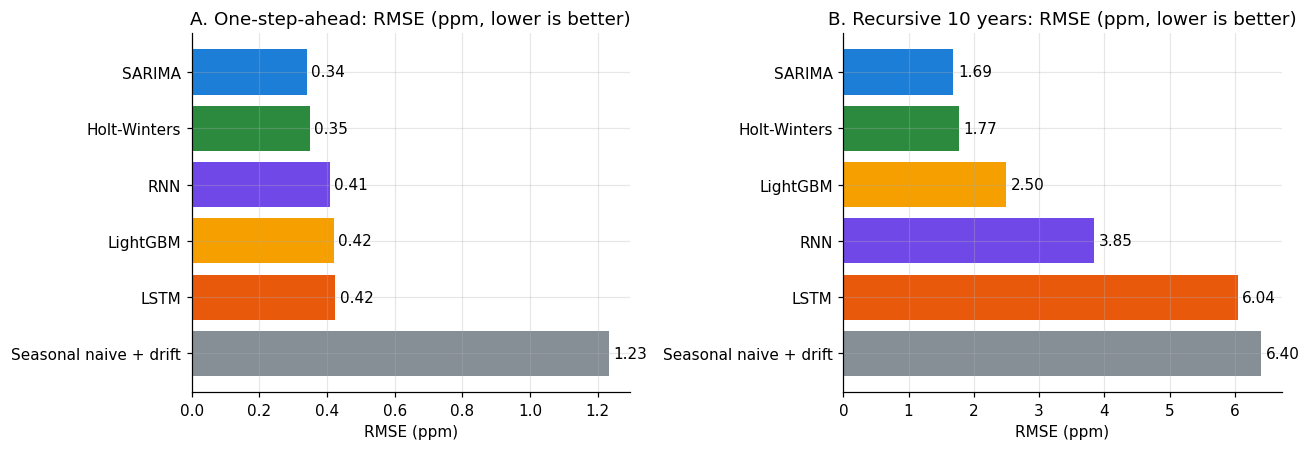

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, tab, title in [(axes[0], table_one.loc[order], "A. One-step-ahead"), (axes[1], table_rec.loc[order], "B. Recursive 10 years")]:
    t = tab.sort_values("RMSE")
    bars = ax.barh(t.index, t["RMSE"], color=[COLORS[m] for m in t.index])
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.invert_yaxis()
    ax.set(title=f"{title}: RMSE (ppm, lower is better)", xlabel="RMSE (ppm)")
plt.tight_layout()
plt.show()

**How fast do errors grow?** Absolute error of each recursive forecast, by months ahead (12-month moving average).

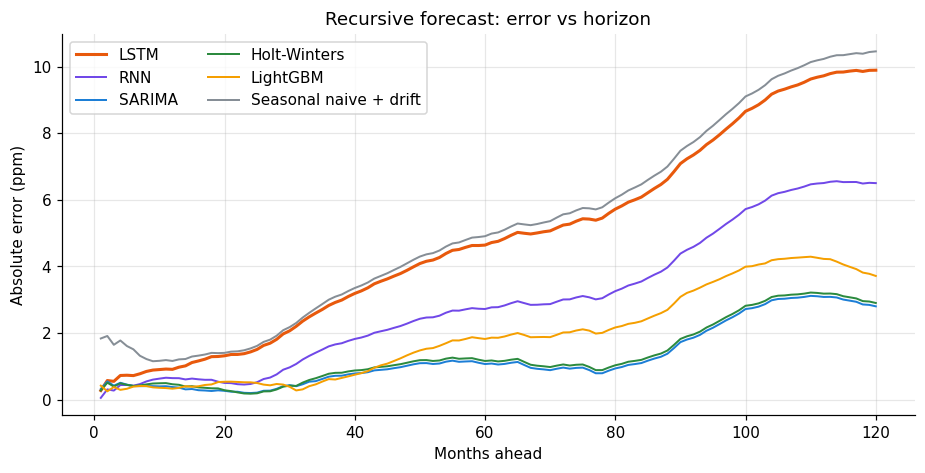

In [22]:
fig, ax = plt.subplots()
for m in order:
    err = pd.Series(np.abs(actual - preds_rec[m])).rolling(12, min_periods=1).mean()
    ax.plot(np.arange(1, H + 1), err, color=COLORS[m], lw=2 if m == "LSTM" else 1.3, label=m)
ax.set(title="Recursive forecast: error vs horizon", xlabel="Months ahead", ylabel="Absolute error (ppm)")
ax.legend(ncol=2)
plt.show()

## 6. Looking ahead: forecast to September 2036

,Sep 2036 (ppm),First month ≥ 440 ppm,First month ≥ 450 ppm
LSTM,444.2,Apr 2031,after 2036
SARIMA,450.1,Apr 2030,Apr 2034


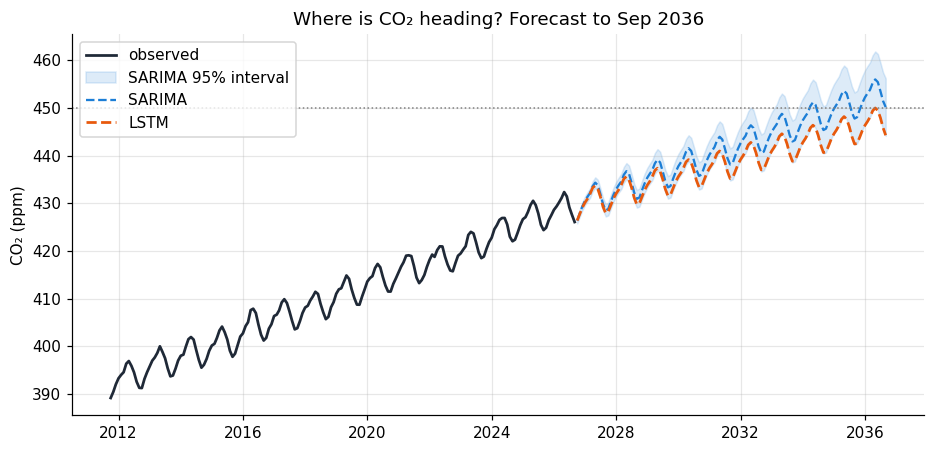

Total run time: 40 s


In [23]:
HF = 120
future_dates = pd.date_range(dates.iloc[-1] + pd.offsets.MonthBegin(), periods=HF, freq="MS")

# LSTM re-trained on all the data (same pipeline)
mu_f, sd_f = d.mean(), d.std()
zf = (d - mu_f) / sd_f
Xf, Yf = make_windows(zf)
lstm_f, _ = train("lstm", Xf, Yf)
fut_lstm = y[-1] + np.cumsum(recursive(lambda w: predict(lstm_f, w)[0], zf, HF) * sd_f + mu_f)

# SARIMA re-fitted on all the data, with 95% prediction interval
sar_f = SARIMAX(yall, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
fc = sar_f.get_forecast(HF)
fut_sar, ci = fc.predicted_mean.values, fc.conf_int(alpha=0.05).values

def first_month_above(values, level):
    idx = np.argmax(values >= level)
    return f"{future_dates[idx]:%b %Y}" if values[idx] >= level else "after 2036"

summary = pd.DataFrame({
    "Sep 2036 (ppm)": [fut_lstm[-1], fut_sar[-1]],
    "First month ≥ 440 ppm": [first_month_above(fut_lstm, 440), first_month_above(fut_sar, 440)],
    "First month ≥ 450 ppm": [first_month_above(fut_lstm, 450), first_month_above(fut_sar, 450)],
}, index=["LSTM", "SARIMA"])
display(summary.round(1))

fig, ax = plt.subplots()
ax.plot(dates[-180:], y[-180:], color=COLORS["actual"], lw=1.8, label="observed")
ax.fill_between(future_dates, ci[:, 0], ci[:, 1], color=COLORS["SARIMA"], alpha=.15, label="SARIMA 95% interval")
ax.plot(future_dates, fut_sar, color=COLORS["SARIMA"], lw=1.5, ls="--", label="SARIMA")
ax.plot(future_dates, fut_lstm, color=COLORS["LSTM"], lw=1.8, ls="--", label="LSTM")
ax.axhline(450, color="gray", ls=":", lw=1)
ax.set(title="Where is CO₂ heading? Forecast to Sep 2036", ylabel="CO₂ (ppm)")
ax.legend(loc="upper left")
plt.show()
print(f"Total run time: {time.time() - T0:.0f} s")

## 7. Optional experiment: does more memory help? (≈ 1 minute)
LSTM vs simple RNN with input windows from 6 to 96 months (one-step RMSE on the test period).

,LSTM,RNN
window (months),,
6,0.531,0.576
12,0.419,0.421
36,0.429,0.407
60,0.418,0.425
96,0.415,0.422


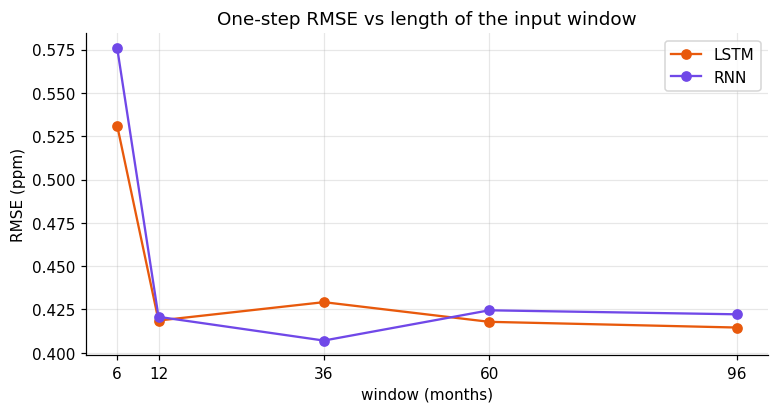

In [24]:
def one_step_rmse(cell, lb):
    Xw, Yw = make_windows(z, lb)
    trw = np.arange(lb, len(z)) < n_train_d
    m, _ = train(cell, Xw[trw], Yw[trw])
    p = prev + predict(m, Xw[~trw]) * sd + mu
    return np.sqrt(np.mean((actual - p) ** 2))

windows = [6, 12, 36, 60, 96]
mem = pd.DataFrame({cell.upper(): [one_step_rmse(cell, lb) for lb in windows] for cell in ["lstm", "rnn"]},
                   index=pd.Index(windows, name="window (months)"))
display(mem.round(3))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(windows, mem["LSTM"], marker="o", color=COLORS["LSTM"], label="LSTM")
ax.plot(windows, mem["RNN"], marker="o", color=COLORS["RNN"], label="RNN")
ax.set(title="One-step RMSE vs length of the input window", xlabel="window (months)", ylabel="RMSE (ppm)", xticks=windows)
ax.legend()
plt.show()

## 8. Conclusions
* **Data:** CO₂ grew from 315.7 ppm (1958) to over 430 ppm (2026), and the growth is accelerating: from 0.86 ppm/year in the 1960s to 2.62 ppm/year in the 2020s (record: +3.52 ppm in 2024). Every year it peaks in May and bottoms out in October.
* **Differencing is essential for the LSTM:** trained on raw levels it cannot go above the values it saw in training (RMSE 21.6 ppm).
* **One-step-ahead:** every learned model is very accurate (R² ≥ 0.997). SARIMA is best (0.34 ppm); the LSTM reaches 0.42 ppm, close to the RNN and LightGBM, and 66% better than seasonal naive + drift.
* **Recursive 10 years:** SARIMA (1.69 ppm) and Holt-Winters (1.77 ppm) win. The LSTM learned the average growth of 1958–2016 and underestimates today's faster growth (6.04 ppm).
* **Memory:** windows of 12 months or more give the same result, and the LSTM performs like the simple RNN: the memory this series needs is about one seasonal cycle.
* **Lesson:** for a single, smooth, regular series, classical models are hard to beat. The LSTM's advantages (long, non-linear and multivariate dependencies) do not appear in this problem.
* Results may vary slightly between machines and library versions, even with a fixed seed.